# Chapitre 7 - Cours 2 : optimisme, Cp, AIC, BIC, nombre effectif de paramètres et dimension VC

Le notebook précédent a montré que l'erreur d'apprentissage $\overline{\mathrm{err}}$ est
trop optimiste. Nous quantifions ici cet **optimisme** (sections 7.4 à 7.9 du livre) et en
déduisons des critères analytiques de sélection de modèle :

1. erreur intra-échantillon, optimisme et formule $\omega = \frac2N\sum\mathrm{Cov}(\hat y_i, y_i)$ ;
2. les critères **Cp** et **AIC**, illustrés sur les données de phonèmes (figure 7.4) ;
3. le **nombre effectif de paramètres** $\mathrm{df}(\mathbf S) = \mathrm{trace}(\mathbf S)$ ;
4. le critère **BIC** et son interprétation bayésienne, comparé à AIC ;
5. la **dimension de Vapnik-Chervonenkis** (figures 7.5 et 7.6).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch07_selection as sel
set_style()

## 1. Erreur intra-échantillon et optimisme

Dans cette section, les entrées $x_1, \dots, x_N$ sont **fixées** et seules les réponses
sont aléatoires. On imagine de **nouvelles** réponses $Y_i^0$ observées aux mêmes points
$x_i$, indépendantes des $y_i$ mais de même loi. L'**erreur intra-échantillon**
(éq. (7.18) du livre) est

$$
\mathrm{Err}_{\mathrm{in}} = \frac1N \sum_{i=1}^N \mathbb E_{Y^0}\big[L(Y_i^0, \hat f(x_i)) \,\big|\, \mathcal T\big].
$$

Elle diffère de $\mathrm{Err}_{\mathcal T}$ uniquement par le lieu des points test : on
évalue aux points d'apprentissage au lieu de points $X^0$ nouveaux.

On définit l'**optimisme** comme l'écart $\mathrm{op} = \mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}}$
(éq. (7.19)), et l'**optimisme moyen** $\omega = \mathbb E_{\mathbf y}(\mathrm{op})$ (éq. (7.20)),
où l'espérance porte sur les réponses d'apprentissage. Pour la perte quadratique (et
d'autres pertes), on a le résultat fondamental (éq. (7.21), démontré dans l'exercice 7.4) :

$$\omega = \frac2N \sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i).$$

Autrement dit,
$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) + \frac2N\sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i). \tag{7.22}$$

> **Intuition.** Plus une observation $y_i$ influence sa propre prédiction $\hat y_i$,
> plus l'erreur d'apprentissage est flatteuse. Un modèle qui interpole ($\hat y_i = y_i$)
> a une covariance maximale $\mathrm{Var}(y_i) = \sigma^2_\varepsilon$ et une erreur
> d'apprentissage nulle.

**Cas linéaire.** Si $\hat{\mathbf y} = \mathbf H\mathbf y$ est un ajustement par
moindres carrés sur $d$ variables (ou fonctions de base) et $Y = f(X) + \varepsilon$ avec
$\mathrm{Var}(\varepsilon) = \sigma_\varepsilon^2$, alors
$\mathrm{Cov}(\hat{\mathbf y}, \mathbf y) = \mathbf H\,\mathrm{Var}(\mathbf y) = \sigma^2_\varepsilon\mathbf H$,
donc $\sum_i \mathrm{Cov}(\hat y_i, y_i) = \sigma^2_\varepsilon\,\mathrm{trace}(\mathbf H) = d\,\sigma^2_\varepsilon$
(éq. (7.23)), et

$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) + 2\,\frac dN\,\sigma^2_\varepsilon. \tag{7.24}$$

L'optimisme croît **linéairement** avec $d$ et décroît comme $1/N$.

Vérifions (7.24) par simulation : $N = 40$ entrées fixées, $f(x) = \sin(2\pi x_1) + x_2$,
régression polynomiale en $x_1$ de degré variable (avec $x_2$), $\sigma_\varepsilon = 1$.
On estime $\mathbb E(\mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}})$ en tirant
beaucoup de vecteurs $\mathbf y$ et, pour chacun, des réponses neuves $\mathbf Y^0$.

In [2]:
rng = np.random.RandomState(0)
N, sig, n_rep = 40, 1.0, 4000
X = rng.rand(N, 2)
fx = np.sin(2 * np.pi * X[:, 0]) + X[:, 1]
degrees = np.arange(1, 11)
opt_mc, d_list = [], []
for deg in degrees:
    B = np.column_stack([X[:, 0] ** j for j in range(1, deg + 1)] + [X[:, 1]])
    H = sel.hat_matrix(B)
    d_list.append(np.trace(H))
    Y = fx + sig * rng.randn(n_rep, N)
    Y0 = fx + sig * rng.randn(n_rep, N)
    Yhat = Y @ H.T
    err = ((Y - Yhat) ** 2).mean(1)
    err_in = ((Y0 - Yhat) ** 2).mean(1)
    opt_mc.append((err_in - err).mean())
d_list = np.array(d_list)

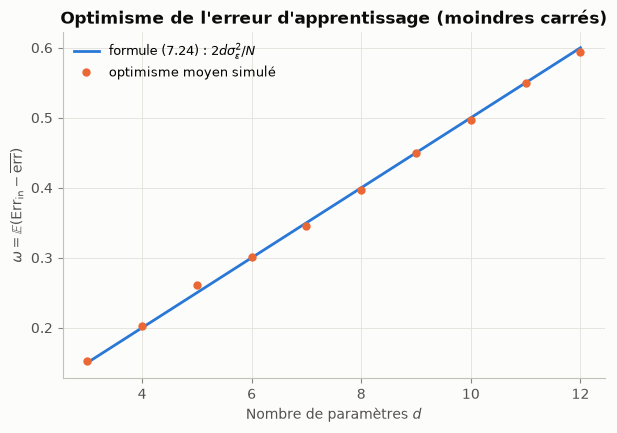

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(d_list, 2 * d_list * sig ** 2 / N, color=BLUE, label=r"formule (7.24) : $2d\sigma_\varepsilon^2/N$")
ax.plot(d_list, opt_mc, "o", color=ORANGE, label="optimisme moyen simulé")
ax.set_xlabel("Nombre de paramètres $d$")
ax.set_ylabel(r"$\omega = \mathbb{E}(\mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}})$")
ax.set_title("Optimisme de l'erreur d'apprentissage (moindres carrés)")
ax.legend()
plt.show()

Les points simulés tombent sur la droite $2d\sigma^2_\varepsilon/N$, **quelle que soit**
la qualité du modèle (même les modèles très biaisés de petit degré) : l'optimisme ne
dépend que du nombre de paramètres et du bruit.

## 2. Critères Cp et AIC

L'idée est simple : estimer l'optimisme et l'**ajouter** à l'erreur d'apprentissage.
Avec $d$ paramètres et la perte quadratique, (7.24) conduit à la statistique de Mallows

$$C_p = \overline{\mathrm{err}} + 2\cdot\frac dN\,\hat\sigma^2_\varepsilon, \tag{7.26}$$

où $\hat\sigma^2_\varepsilon$ estime la variance du bruit, typiquement à partir de l'erreur
quadratique moyenne d'un modèle **peu biaisé** (par exemple le modèle complet).

Le **critère d'information d'Akaike** (AIC) généralise cette idée à toute
vraisemblance. Si $\hat\theta$ est l'estimateur du maximum de vraisemblance d'un modèle à
$d$ paramètres et $\mathrm{loglik} = \sum_{i=1}^N \log \Pr_{\hat\theta}(y_i)$, on dispose
de l'approximation asymptotique (éq. (7.27))
$-2\,\mathbb E[\log\Pr_{\hat\theta}(Y)] \approx -\frac2N\mathbb E[\mathrm{loglik}] + 2\frac dN$,
d'où

$$\mathrm{AIC} = -\frac2N\cdot\mathrm{loglik} + 2\cdot\frac dN. \tag{7.29}$$

**Lien avec Cp.** Dans le modèle gaussien de variance $\sigma^2_\varepsilon$ connue,
$$-2\,\mathrm{loglik} = \sum_i \frac{(y_i - \hat f(x_i))^2}{\sigma^2_\varepsilon} + \text{constante}
= \frac{N\,\overline{\mathrm{err}}}{\sigma^2_\varepsilon} + \text{constante},$$
donc $\mathrm{AIC} = \big(\overline{\mathrm{err}} + 2\frac dN\sigma^2_\varepsilon\big)/\sigma^2_\varepsilon + \text{constante}$ :
AIC et Cp sont **équivalents** (même minimiseur). Pour une famille de modèles indexée
par un paramètre de réglage $\alpha$, on minimise
$\mathrm{AIC}(\alpha) = \overline{\mathrm{err}}(\alpha) + 2\frac{d(\alpha)}N\hat\sigma^2_\varepsilon$ (éq. (7.30)).

> **Remarque.** La formule $\sum_i\mathrm{Cov}(\hat y_i, y_i) = d\sigma^2_\varepsilon$
> suppose que les $d$ fonctions de base sont fixées **à l'avance**. Si l'on choisit les
> $d$ meilleures variables parmi $p$ en regardant les données, l'optimisme est plus grand :
> le nombre effectif de paramètres dépasse $d$. Nous le vérifierons plus bas.

### 2.1 Figure 7.4 : AIC pour les données de phonèmes

On reprend l'exemple de la section 5.2.3 : distinguer les phonèmes « aa » et « ao » à
partir du log-périodogramme $x(f)$ mesuré en 256 fréquences. La régression logistique
utilise une **fonction coefficient** lisse
$$\log\frac{\Pr(\text{aa}\mid x)}{\Pr(\text{ao}\mid x)} = \beta_0 + \sum_{f=1}^{256} x(f)\beta(f),
\qquad \beta(f) = \sum_{m=1}^M h_m(f)\,\theta_m,$$
où les $h_m$ forment une base de $M$ splines cubiques naturelles à nœuds équirépartis.
Le modèle est donc une régression logistique sur les $M$ variables dérivées
$\mathbf x^{*} = \mathbf H^T\mathbf x$, avec $d = M + 1$ paramètres (constante comprise).
Pour $M = 256$, on prend $\mathbf H = I$ (aucune contrainte de lissage).

In [4]:
ph = datasets.load_phoneme()
ph = ph[ph["g"].isin(["aa", "ao"])]
Xph = ph.filter(like="x.").to_numpy(float)
yph = (ph["g"] == "aa").to_numpy(int)
rng = np.random.RandomState(0)
perm = rng.permutation(len(yph))
itr, ite = perm[:1000], perm[1000:]
print("apprentissage :", len(itr), "observations ; test :", len(ite))

apprentissage : 1000 observations ; test : 717


On ajuste la régression logistique par l'algorithme de Newton-Raphson (IRLS, section
4.4.1), codé dans `esl.ch07_selection.logistic_regression`. Pour la stabilité numérique,
on orthonormalise d'abord les colonnes de $[\mathbf 1, \mathbf X\mathbf H]$ (décomposition
QR) : cela change la paramétrisation mais **pas** le modèle ajusté.

In [5]:
freqs = np.arange(1, 257) / 256
M_list = [2, 4, 8, 16, 32, 64, 128, 256]
rows = []
for M in M_list:
    Hb = np.eye(256) if M == 256 else sel.natural_spline_basis(freqs, np.linspace(freqs[0], 1, M))
    Z, _ = np.linalg.qr(np.column_stack([np.ones(len(yph)), Xph @ Hb]))
    Z *= np.sqrt(len(yph))
    b = sel.logistic_regression(Z[itr], yph[itr])
    ll_tr = sel.logistic_loglik(Z[itr], yph[itr], b)
    ll_te = sel.logistic_loglik(Z[ite], yph[ite], b)
    d = M + 1
    rows.append(dict(M=M, dev_tr=-2 * ll_tr / len(itr), dev_te=-2 * ll_te / len(ite),
                     aic=sel.aic_loglik(ll_tr, d, len(itr)),
                     mis_tr=np.mean((Z[itr] @ b > 0) != yph[itr]),
                     mis_te=np.mean((Z[ite] @ b > 0) != yph[ite])))
import pandas as pd
tab = pd.DataFrame(rows).set_index("M")
tab.round(3)

,dev_tr,dev_te,aic,mis_tr,mis_te
M,,,,,
2,1.104,1.190,1.110,0.276,0.312
4,1.056,1.096,1.066,0.256,0.264
8,0.877,0.851,0.895,0.209,0.192
16,0.820,0.770,0.854,0.190,0.163
32,0.774,0.767,0.840,0.172,0.166
64,0.722,0.796,0.852,0.165,0.184
128,0.646,0.919,0.904,0.144,0.211
256,0.464,1.634,0.978,0.087,0.238


Pour la perte 0-1, la formule de l'optimisme n'est pas exacte, mais on peut tout de même
l'utiliser comme le fait le livre : $\overline{\mathrm{err}} + 2\frac dN\hat\sigma^2$ avec
$\hat\sigma^2 = \bar p(1-\bar p)$ une estimation grossière de la variance d'une réponse
binaire (ici $\bar p$ est la proportion de « aa »).

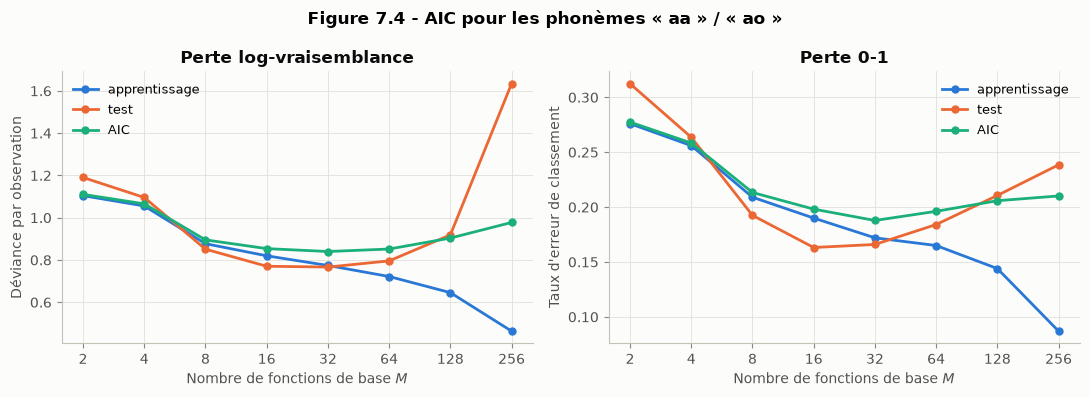

In [6]:
pbar = yph[itr].mean()
tab["aic_01"] = tab["mis_tr"] + 2 * (tab.index + 1) / len(itr) * pbar * (1 - pbar)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (tr, te, aic, lab) in zip(axes, [("dev_tr", "dev_te", "aic", "Déviance par observation"),
                                         ("mis_tr", "mis_te", "aic_01", "Taux d'erreur de classement")]):
    ax.plot(M_list, tab[tr], "o-", color=BLUE, label="apprentissage")
    ax.plot(M_list, tab[te], "o-", color=ORANGE, label="test")
    ax.plot(M_list, tab[aic], "o-", color=COLORS[2], label="AIC")
    ax.set_xscale("log", base=2)
    ax.set_xticks(M_list, [str(m) for m in M_list])
    ax.set_xlabel("Nombre de fonctions de base $M$")
    ax.set_ylabel(lab)
    ax.legend()
axes[0].set_title("Perte log-vraisemblance")
axes[1].set_title("Perte 0-1")
fig.suptitle("Figure 7.4 - AIC pour les phonèmes « aa » / « ao »", fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
print("M minimisant l'AIC (déviance) :", tab["aic"].idxmin(), "; M minimisant l'erreur test (déviance) :", tab["dev_te"].idxmin())

M minimisant l'AIC (déviance) : 32 ; M minimisant l'erreur test (déviance) : 32


L'AIC suit bien la courbe de test **sauf** pour le modèle extrêmement sur-paramétré
$M = 256$ ($257$ paramètres pour $1000$ observations), où l'approximation asymptotique
n'est plus valable. Il conduit à choisir un nombre modéré de fonctions de base, proche de
celui qui minimise l'erreur test.

## 3. Nombre effectif de paramètres

Une méthode d'ajustement est **linéaire** si $\hat{\mathbf y} = \mathbf S\mathbf y$ où la
matrice $N\times N$ $\mathbf S$ dépend des $x_i$ mais pas des $y_i$ (éq. (7.31)) :
régression sur une base fixée, ridge, splines de lissage, $k$ plus proches voisins…
On définit alors le **nombre effectif de paramètres** (ou degrés de liberté effectifs)

$$\mathrm{df}(\mathbf S) = \mathrm{trace}(\mathbf S). \tag{7.32}$$

Pour un projecteur orthogonal sur $M$ fonctions de base, on retrouve $M$.

C'est la bonne quantité à mettre dans Cp : pour un modèle à bruit additif,
$\sum_i \mathrm{Cov}(\hat y_i, y_i) = \mathrm{trace}(\mathbf S)\,\sigma^2_\varepsilon$
(exercice 7.5). Cela motive la définition générale, valable même pour une méthode non
linéaire :

$$\mathrm{df}(\hat{\mathbf y}) = \frac{\sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i)}{\sigma^2_\varepsilon}. \tag{7.33}$$

Vérifions numériquement l'égalité de (7.32) et (7.33) pour une **spline cubique de
lissage**, qui minimise $\sum_i (y_i - g(x_i))^2 + \lambda\int g''(t)^2\,dt$ (section 5.4) :
sa matrice de lissage $\mathbf S_\lambda$ est calculée par `sel.smoothing_spline_matrix`.

In [8]:
rng = np.random.RandomState(0)
N = 50
xs = np.sort(rng.rand(N))
fs = np.sin(4 * xs)
lams = np.logspace(-7, 0, 8)
df_tr, df_mc = [], []
for lam in lams:
    S = sel.smoothing_spline_matrix(xs, lam)
    df_tr.append(sel.df_trace(S))
    df_mc.append(sel.df_monte_carlo(lambda y: S @ y, fs, sigma=1.0, n_rep=3000, rng=rng))
pd.DataFrame({"lambda": ["%.0e" % l for l in lams], "trace(S)": np.round(df_tr, 2),
              "sum Cov / sigma^2 (simulation)": np.round(df_mc, 2)})

,lambda,trace(S),sum Cov / sigma^2 (simulation)
0,1e-07,34.35,34.26
1,1e-06,24.86,24.93
2,1e-05,16.10,16.11
3,1e-04,9.90,9.95
4,1e-03,6.11,6.13
5,1e-02,3.91,3.91
6,1e-01,2.68,2.71
7,1e+00,2.11,2.05


Les deux colonnes coïncident aux fluctuations de Monte-Carlo près. Quand $\lambda \to 0$
la spline interpole ($\mathrm{df} \to N$) ; quand $\lambda \to \infty$ elle devient la
droite des moindres carrés ($\mathrm{df} \to 2$).

### 3.1 Sélection adaptative : le « vrai » nombre de paramètres dépasse $d$

Utilisons maintenant la définition (7.33) pour une méthode **non linéaire** : la
régression pas à pas ascendante qui choisit $d$ variables parmi $p = 20$. Pour mettre en
évidence l'effet de la sélection, on prend une réponse de **pur bruit**
($f = 0$, $\sigma_\varepsilon = 1$), $N = 50$, et l'on estime
$\sum_i\mathrm{Cov}(\hat y_i, y_i)/\sigma^2_\varepsilon$ par simulation.

In [9]:
rng = np.random.RandomState(1)
N, P, n_rep, dmax = 50, 20, 400, 10
Xa = rng.randn(N, P)
Y = rng.randn(n_rep, N)
fits = np.zeros((n_rep, dmax + 1, N))
for r in range(n_rep):
    order = sel.forward_stepwise(Xa, Y[r], max_size=dmax)
    for d in range(dmax + 1):
        fits[r, d] = sel.ols_fit_predict(Xa[:, order[:d]], Y[r], Xa[:, order[:d]]) if d else Y[r].mean()
cov = ((Y - Y.mean(0))[:, None, :] * (fits - fits.mean(0))).sum(0) / (n_rep - 1)
df_adapt = cov.sum(1)   # sigma = 1

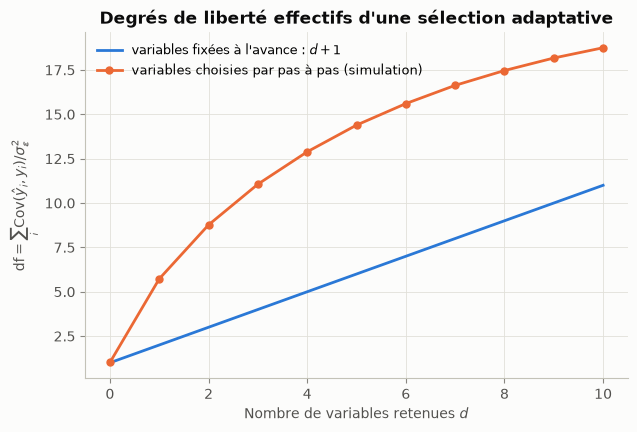

In [10]:
dd = np.arange(dmax + 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(dd, dd + 1, color=BLUE, label="variables fixées à l'avance : $d+1$")
ax.plot(dd, df_adapt, "o-", color=ORANGE, label="variables choisies par pas à pas (simulation)")
ax.set_xlabel("Nombre de variables retenues $d$")
ax.set_ylabel(r"$\mathrm{df} = \sum_i \mathrm{Cov}(\hat y_i, y_i)/\sigma_\varepsilon^2$")
ax.set_title("Degrés de liberté effectifs d'une sélection adaptative")
ax.legend()
plt.show()

Choisir les variables en regardant les données « consomme » des degrés de liberté
supplémentaires : avec $d = 1$ variable choisie parmi 20, le nombre effectif de paramètres
est déjà bien supérieur à 2. Utiliser Cp avec $d$ naïf sous-estimerait l'optimisme.

## 4. Le critère BIC et l'approche bayésienne

Le **critère d'information bayésien** s'applique, comme l'AIC, aux ajustements par
maximum de vraisemblance :

$$\mathrm{BIC} = -2\cdot\mathrm{loglik} + (\log N)\cdot d. \tag{7.35}$$

Dans le cas gaussien à variance connue, comme plus haut,
$\mathrm{BIC} = \frac N{\sigma^2_\varepsilon}\big[\overline{\mathrm{err}} + (\log N)\frac dN\sigma^2_\varepsilon\big]$
(éq. (7.36)) : c'est l'AIC avec le facteur $2$ remplacé par $\log N$. Dès que
$N > e^2 \approx 7{,}4$, le BIC **pénalise plus** la complexité et favorise des modèles
plus simples.

**Motivation bayésienne.** On se donne des modèles candidats $\mathcal M_1, \dots, \mathcal M_M$,
de paramètres $\theta_m$, avec des lois a priori $\Pr(\theta_m\mid\mathcal M_m)$. Par la
formule de Bayes, la probabilité a posteriori d'un modèle au vu des données $\mathbf Z$ est

$$\Pr(\mathcal M_m\mid\mathbf Z) \propto \Pr(\mathcal M_m)\,\Pr(\mathbf Z\mid\mathcal M_m)
= \Pr(\mathcal M_m)\int \Pr(\mathbf Z\mid\theta_m, \mathcal M_m)\Pr(\theta_m\mid\mathcal M_m)\,d\theta_m. \tag{7.37}$$

Le rapport $\Pr(\mathbf Z\mid\mathcal M_m)/\Pr(\mathbf Z\mid\mathcal M_\ell)$ s'appelle le
**facteur de Bayes** (éq. (7.39)).

L'intégrale (la « vraisemblance marginale ») n'est pas explicite en général. Quand $N$ est
grand, la vraisemblance est très concentrée autour de $\hat\theta_m$ et l'on peut
l'approcher par une gaussienne (**approximation de Laplace** : développement de Taylor à
l'ordre 2 du logarithme autour du maximum). Le volume de cette gaussienne en dimension
$d_m$ décroît comme $N^{-d_m/2}$, ce qui donne (éq. (7.40))

$$\log\Pr(\mathbf Z\mid\mathcal M_m) = \log\Pr(\mathbf Z\mid\hat\theta_m, \mathcal M_m) - \frac{d_m}2\log N + O(1).$$

Avec un a priori uniforme sur les modèles, maximiser la probabilité a posteriori revient
donc (au $O(1)$ près) à **minimiser le BIC**. On en déduit même des probabilités a
posteriori approchées $\Pr(\mathcal M_m\mid\mathbf Z) \approx e^{-\mathrm{BIC}_m/2}\big/\sum_\ell e^{-\mathrm{BIC}_\ell/2}$ (éq. (7.41)).